# Analyzing BERT Hidden States Using Salient Token Patterns

## Beer concept-shortcut analysis

# Expected Shortcuts in the Beer Dataset

## 1. Concept Occurrence (`occurrence1`)

**Shortcut definition:** The presence of aroma-related versus appearance-related content is artificially correlated with the palate rating.

- **Class 0 (palate 0.4):** Appearance-related content is expected.
- **Class 1 (palate 0.6):** Appearance content is more likely than aroma content.
- **Class 2 (palate 0.8):** Aroma content is more likely than appearance content.
- **Class 3 (palate 1.0):** Aroma-related content is expected.

### Expected shortcut vocabulary and patterns

| Class | Expected vocabulary | Example n-grams |
|---|---|---|
| 0 | appearance, foam, head, color, lacing, pours | white head, golden color, thick foam |
| 3 | aroma, smell, nose, scent, fragrance, malt, citrus | citrus aroma, fruity smell, floral notes |

**Expected model behavior:** BERT may learn to associate appearance-related content with low palate ratings and aroma-related content with high palate ratings, regardless of the actual palate description.

The shortcut depends on **which concept is present**, not whether that concept is described positively or negatively.

---

## 2. Concept Correlation (`correlation1`)

**Shortcut definition:** The rating of an injected aroma description is artificially correlated with the palate rating.

- **Class 0 (palate 0.4):** Aroma description with rating 0.4.
- **Class 1 (palate 0.6):** Aroma description with rating 0.6.
- **Class 2 (palate 0.8):** Aroma description with rating 0.8.
- **Class 3 (palate 1.0):** Aroma description with rating 1.0.

### Expected shortcut vocabulary and patterns

| Class | Expected vocabulary | Example n-grams |
|---|---|---|
| 0 | unpleasant, sour, stale, awful, weak | unpleasant aroma, terrible smell, stale odor |
| 3 | wonderful, excellent, pleasant, fantastic, aromatic | wonderful aroma, pleasant smell, excellent fragrance |

**Expected model behavior:** BERT may learn to predict palate ratings from the evaluation of the aroma rather than from the actual palate description.

The shortcut depends on **how the aroma is evaluated**, not merely whether aroma-related vocabulary appears.

---

## 3. Shortcut Strength

Both experiments have three settings:

| Setting | Strength | Description |
|---|---|---|
| `occurrence1` / `correlation1` | Strongest (λ = 1.0) | Most reliable shortcut relationship |
| `occurrence2` / `correlation2` | Medium (λ = 0.8) | Less reliable shortcut relationship |
| `occurrence3` / `correlation3` | Weakest (λ = 0.6) | Least reliable shortcut relationship |

## 4. Expected Patterns in the Analysis

**For Occurrence:**

Class-specific saliency or representation changes may involve appearance-related features for class 0 and aroma-related features for class 3.

**For Correlation:**

Class-specific saliency or representation changes may involve negative aroma descriptions for class 0 and positive aroma descriptions for class 3.

### Important limitations

- The listed tokens and n-grams are hypotheses, not verified shortcut vocabulary supplied by the authors.
- Legitimate palate features such as `watery`, `thin`, `creamy`, and `smooth` may also be highly salient.
- FP-Growth discovers co-occurring token sets, not necessarily contiguous n-grams.
- Generic sentiment words are not automatically shortcuts; their origin in the injected aroma content must be verified.
- High saliency or a large representation shift alone does not establish shortcut reliance.

**Validation criterion:** Shortcut attribution requires evidence that the detected features are associated with the injected content and influence model predictions, for example through controlled removal or replacement of that content.

---
## S1 Vocabulary Construction

### Imports

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import os

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from datasets import Dataset
from transformers import BertModel, BertTokenizerFast, BertForSequenceClassification
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth
from IPython.display import display


/Users/leosteiner/Desktop/transformer-shortcut-mitigation/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load Models

Load the fine-tuned BERT classifier for the selected Beer shortcut dataset and the pretrained `bert-base-uncased` encoder.

In [2]:
# Select the Beer shortcut variant and matching checkpoint.
EXPERIMENT = "correlation1"  # Alternative shortcut variant.
MODEL_SEED = 42
PROJECT_ROOT = Path.cwd().resolve()  # Paths are resolved relative to the repository root.

if EXPERIMENT not in ("occurrence1", "correlation1"):
    raise ValueError("EXPERIMENT must be 'occurrence1' or 'correlation1'")

dataset_path = PROJECT_ROOT / "beer_pipeline_datasets" / EXPERIMENT / "dev.csv"
model_name = f"bert-beer-{EXPERIMENT}-seed{MODEL_SEED}"
model_candidates = [PROJECT_ROOT / model_name, PROJECT_ROOT / "beer_models" / model_name]
model_path = next((p for p in model_candidates if (p / "config.json").is_file()), None)
if model_path is None:
    raise FileNotFoundError(f"Model not found. Checked: {model_candidates}")
if not dataset_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {dataset_path}")

print("Model:", model_path)
print("Dataset:", dataset_path)

tokenizer = BertTokenizerFast.from_pretrained(str(model_path))
ft_bert = BertForSequenceClassification.from_pretrained(str(model_path))
assert ft_bert.config.num_labels == 4, "Expected 4 Beer palate classes"

pretrained_name = "bert-base-uncased"
pt_bert = BertModel.from_pretrained(pretrained_name)


Model: /Users/leosteiner/Desktop/transformer-shortcut-mitigation/bert-beer-correlation1-seed42
Dataset: /Users/leosteiner/Desktop/transformer-shortcut-mitigation/beer_pipeline_datasets/correlation1/dev.csv


### Load the Development Dataset

In [3]:

df_dev = pd.read_csv(dataset_path).dropna(subset=["text", "label"]).copy()
df_dev["text"] = df_dev["text"].astype(str)

# Convert palate ratings to the classifier label IDs.
RATING_TO_ID = {0.4: 0, 0.6: 1, 0.8: 2, 1.0: 3}
ID_TO_RATING = {v: k for k, v in RATING_TO_ID.items()}
ratings = pd.to_numeric(df_dev["label"], errors="raise").round(1)
if set(ratings.unique()).issubset(RATING_TO_ID):
    df_dev["label"] = ratings.map(RATING_TO_ID).astype(int)
elif set(ratings.unique()).issubset({0, 1, 2, 3}):
    df_dev["label"] = ratings.astype(int)
else:
    raise ValueError(f"Unexpected Beer labels: {sorted(ratings.unique())}")

dev_data = Dataset.from_pandas(df_dev[["text", "label"]].reset_index(drop=True), preserve_index=False)
print("Dev reviews:", len(dev_data), "True class counts:", df_dev["label"].value_counts().sort_index().to_dict())


Dev reviews: 2000 True class counts: {0: 325, 1: 733, 2: 435, 3: 507}


### Select the Compute Device

In [4]:
# Select MPS, CUDA, or CPU.
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

pt_bert = pt_bert.to(device)
ft_bert = ft_bert.to(device)
ft_bert.eval()
pt_bert.eval()
print("Device:", device)


Device: mps


### Grad-L2 Input Saliency

Token saliency is calculated from the L2 norm of the gradient of the predicted-class logit with respect to each input token embedding.

Reference: [Understanding Text Classification Data and Models Using Aggregated Input Salience](https://arxiv.org/abs/2211.05485)

In [5]:
def grad_l2_saliency(
    text: str,
    model,
    tokenizer,
    device,
    target_class: int | None = None,
    max_length: int = 512
):
    """
    Compute Grad-L2 saliency for one input text.

    Returns:
        tokens: list[str]          # wordpiece tokens incl. special tokens
        saliency: np.ndarray       # shape (seq_len,)
        input_ids: np.ndarray      # token ids (same length as saliency)
    """
    model.eval()

    # Tokenize the review.
    enc = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=max_length
    )
    input_ids = enc["input_ids"].to(device)           # [batch_size, sequence_length]
    attention_mask = enc["attention_mask"].to(device) # [batch_size, sequence_length]
    token_type_ids = enc.get("token_type_ids")
    if token_type_ids is not None:
        token_type_ids = token_type_ids.to(device)

    # Obtain differentiable word embeddings.
    with torch.no_grad():
        word_embeds = model.bert.embeddings.word_embeddings(input_ids)
    word_embeds = word_embeds.detach().requires_grad_(True)  # [batch_size, sequence_length, hidden_size]

    # Forward pass with inputs_embeds enables input-gradient extraction.
    model.zero_grad()
    outputs = model(
        inputs_embeds=word_embeds, # Forward pass uses embeddings instead of input_ids.
        attention_mask=attention_mask,
        token_type_ids=token_type_ids
    )
    logits = outputs.logits  # [batch_size, num_labels]

    # Select the logit for the predicted class unless a target is supplied.
    if target_class is None:
        target_class = logits.argmax(dim=-1).item()  # Predicted class index.

    # Extract the scalar logit used for backpropagation.
    score = logits[0, target_class] # Index logits by example and target class.

    # Backpropagate the selected logit through the token embeddings.
    score.backward()

    grads = word_embeds.grad  # Token-level embedding gradients: [batch_size, sequence_length, hidden_size].

    # Compute the L2 norm of each token gradient.
    saliency = torch.norm(grads, p=2, dim=-1).squeeze(0)  # Reduce [1, L, H] to [L] along the hidden dimension.

    # Convert the saliency vector to NumPy.
    saliency = saliency.detach().cpu().numpy()
    input_ids_cpu = input_ids.squeeze(0).detach().cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(input_ids_cpu)

    return tokens, saliency, input_ids_cpu


### Predicted-Class Groups

The fine-tuned classifier assigns a predicted palate class to each development example. These predictions define four disjoint groups for class-specific saliency analysis and pattern mining.

In [6]:
def predict_labels(dataset_split, model, tokenizer, device, batch_size=32, max_length=512):
    model.eval()
    loader = DataLoader(dataset_split, batch_size=batch_size, shuffle=False)

    all_preds = []
    with torch.no_grad():
        for batch in loader:
            texts = batch["text"]
            enc = tokenizer(
                list(texts),
                return_tensors="pt",
                truncation=True,
                padding=True,
                max_length=max_length,
            ).to(device)

            logits = model(**enc).logits  # Four class logits per review.
            preds = logits.argmax(dim=-1).cpu()
            all_preds.extend(preds.tolist())

    return all_preds

dev_preds = np.asarray(predict_labels(dev_data, ft_bert, tokenizer, device), dtype=np.int64)
class_indices = {c: np.flatnonzero(dev_preds == c).tolist() for c in range(4)}

print("Predicted class counts:")
for c, indices in class_indices.items():
    print(f"  Class {c} (palate {ID_TO_RATING[c]:.1f}): {len(indices)} reviews")
assert sum(map(len, class_indices.values())) == len(dev_data)


Predicted class counts:
  Class 0 (palate 0.4): 292 reviews
  Class 1 (palate 0.6): 657 reviews
  Class 2 (palate 0.8): 513 reviews
  Class 3 (palate 1.0): 538 reviews


### Select the Ten Most Salient Vocabulary Tokens

For each review, repeated occurrences of a WordPiece token ID are represented by their maximum absolute saliency. The ten token IDs with the highest values are retained.

In [7]:
def topk_vocab_tokens_with_maxpos(input_ids, saliency, top_k=10, exclude_special_ids=None):
    """
    For one sentence:
    - For each vocab token_id, keep the maximum |saliency| value observed in this sentence,
      and the token position where that maximum occurs.
    - Return the top_k token_ids ranked by that max |saliency|.

    Output format (length <= top_k):
      [{"token_id": int, "position": int, "saliency": float}, ...]
    """
    exclude_special_ids = set(exclude_special_ids or [])
    best = {}  # token_id -> (maximum absolute saliency, selected position)

    for pos, (tok_id, s) in enumerate(zip(input_ids, saliency)):
        tok_id = int(tok_id)
        if tok_id in exclude_special_ids:
            continue

        a = abs(float(s))
        if (tok_id not in best) or (a > best[tok_id][0]):
            best[tok_id] = (a, int(pos))

    if not best:
        return []

    items = [(tok_id, a, pos) for tok_id, (a, pos) in best.items()]
    items.sort(key=lambda x: x[1], reverse=True)
    items = items[:top_k]

    return [{"token_id": tok_id, "saliency": a, "position": pos} for tok_id, a, pos in items]

### S1 Vocabulary Matrix

Each selected review is represented by a vocabulary-sized saliency vector. The entry for a token ID contains its maximum absolute Grad-L2 saliency within the review; all entries outside the top ten are set to zero. The vectors are stacked into a matrix and L2-normalized row by row.

Each row corresponds to a review, and each column corresponds to a WordPiece vocabulary item:

```text
          column dimension → |V| (S1 vector)
        ┌──────────────────────────────────────────────┐
 row 1  │ r(1)[0]   r(1)[1]   r(1)[2]   ...   r(1)[V-1]│
 row 2  │ r(2)[0]   r(2)[1]   r(2)[2]   ...   r(2)[V-1]│
   .    │    .         .         .              .      │
 row N  │ r(N)[0]   r(N)[1]   r(N)[2]   ...   r(N)[V-1]│
        └──────────────────────────────────────────────┘
```


In [8]:
def saliency_to_vocab_vector(input_ids, saliency, vocab_size, top_k=10, exclude_special_ids=None):
    """
    Implements S1 from the paper: a |V|-dim vector with the
    max |saliency| per vocab item, zeroed except for top-k entries.
    """
    r = np.zeros(vocab_size, dtype=np.float32) # Allocate one entry per BERT vocabulary token.
    exclude_special_ids = set(exclude_special_ids or [])

    for tok_id, s in zip(input_ids, saliency):
        tok_id = int(tok_id)
        if tok_id in exclude_special_ids:
            continue
        r[tok_id] = max(r[tok_id], abs(float(s))) # Retain the maximum absolute saliency for each token ID.

    if top_k is not None and top_k < vocab_size:
        # Zero out all but the highest-scoring vocabulary entries.
        if np.count_nonzero(r) > top_k: # Apply sparsification only when more than top_k entries are nonzero.
            top_idx = np.argpartition(r, -top_k)[-top_k:] # Select the indices of the top_k values.
            mask = np.zeros_like(r)
            mask[top_idx] = r[top_idx]
            r = mask

    return r


def build_salience_vocab_matrix_from_indices(
    dataset_split,
    indices,
    model,
    tokenizer,
    device,
    top_k=10,
    max_length=512,
):
    """Build a row-normalized vocabulary salience matrix for selected dataset indices.

    For each text, computes token saliency, aggregates the top-k salient tokens into a
    vocabulary-sized vector, and returns the stacked matrix along with the source texts
    and per-example top-k token metadata including raw and normalized saliency scores.
    """
    vocab_size = tokenizer.vocab_size
    R_rows = []
    texts = []
    salient_token_info = [] # Collect the selected text indices and token metadata.

    special_ids = tokenizer.all_special_ids  


    for idx in tqdm(indices):
        text = dataset_split[idx]["text"]
        tokens, sal, ids = grad_l2_saliency(
            text, model, tokenizer, device, max_length=max_length
        )
        r = saliency_to_vocab_vector(ids, sal, vocab_size, top_k=top_k, exclude_special_ids=special_ids)
        R_rows.append(r)
        texts.append(text)


        # Record the highest-saliency position of each selected token ID.
        topk_vocab = topk_vocab_tokens_with_maxpos(
            ids, sal, top_k=top_k, exclude_special_ids=special_ids
        )
        salient_token_info.append({
            "dataset_idx": idx,
            "text": text,
            "topk_vocab": topk_vocab
        })

    R_vocab = np.stack(R_rows, axis=0)
    # L2-normalize each review-level S1 vector.
    norms = np.linalg.norm(R_vocab, axis=1, keepdims=True) + 1e-12
    R_vocab = R_vocab / norms
    # Store raw and normalized saliency values for the selected tokens.
    for row_i, info in enumerate(salient_token_info):
        for item in info["topk_vocab"]:
            tok_id = int(item["token_id"])
            item["saliency_raw"] = float(item["saliency"])              # Maximum absolute token saliency before row normalization.
            item["saliency_norm"] = float(R_vocab[row_i, tok_id])       # Corresponding entry in the row-normalized S1 matrix.

    return R_vocab, texts, salient_token_info

### Construct Four S1 Vocabulary Matrices

One row-normalized S1 matrix is constructed for each predicted class, using the ten most salient unique token IDs per review. All four matrices share the same BERT vocabulary. Each development example belongs to exactly one predicted-class group.

In [9]:
# Construct a top-10 S1 saliency matrix for each predicted class.
# Every development review contributes to its predicted-class group.
saliency_by_class = {}

for c in range(4):
    indices = class_indices[c]
    if not indices:
        raise ValueError(f"Predicted class {c} is empty; cannot mine this class")

    print(f"\nClass {c}, {len(indices)} reviews: computing top-10 Grad-L2 saliency")
    R_vocab, texts, salient_token_info = build_salience_vocab_matrix_from_indices(
        dev_data, indices, ft_bert, tokenizer, device, top_k=10
    )

    saliency_by_class[c] = {
        "R_vocab": R_vocab,
        "texts": texts,
        "salient_token_info": salient_token_info,
    }

print("\nFour S1 matrices constructed (one per class, top-10 only).")


Class 0, 292 reviews: computing top-10 Grad-L2 saliency


  0%|          | 0/292 [00:00<?, ?it/s]huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
100%|██████████| 292/292 [00:26<00:00, 11.04it/s]



Class 1, 657 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 657/657 [00:42<00:00, 15.42it/s]



Class 2, 513 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 513/513 [00:29<00:00, 17.44it/s]



Class 3, 538 reviews: computing top-10 Grad-L2 saliency


100%|██████████| 538/538 [00:31<00:00, 17.27it/s]


Four S1 matrices constructed (one per class, top-10 only).


## Frequent Pattern Mining

FP-Growth is applied to the salient token sets of each predicted class.

### FP-Growth Support and Saliency Scoring

Each class is mined separately from transactions containing the ten selected token IDs per review. Patterns contain between one and four tokens and must occur in at least `MIN_SUPPORT_COUNT` reviews within their predicted-class group.

The resulting DataFrames include:

- `support`: fraction of reviews in the predicted-class group containing the pattern.
- `support_count`: number of supporting reviews in that group.
- `saliency_score`: mean normalized saliency of the pattern's tokens over supporting reviews.
- `score`: `support * saliency_score`.

FP-Growth identifies co-occurring token sets rather than necessarily contiguous n-grams. `ordered_ids` uses token positions from the first supporting review to provide one observed ordering.

In [32]:
MIN_SUPPORT_COUNT = 8  # Minimum supporting review count within each predicted class.
MAX_LEN = 4


def mine_frequent_itemsets(salient_token_info, class_id):
    # Construct per-review transactions and lookup tables.
    transactions = []
    pos_lookup = []
    saliency_lookup = []

    for item in salient_token_info:
        toks = [int(t["token_id"]) for t in item["topk_vocab"]]
        transactions.append(toks)
        pos_lookup.append({int(t["token_id"]): int(t["position"]) for t in item["topk_vocab"]})
        saliency_lookup.append({int(t["token_id"]): float(t["saliency_norm"]) for t in item["topk_vocab"]})

    n_rows = len(transactions)
    if n_rows < MIN_SUPPORT_COUNT:
        raise ValueError(f"Class {class_id} has only {n_rows} reviews; lower MIN_SUPPORT_COUNT")

    te = TransactionEncoder()
    X = te.fit(transactions).transform(transactions)
    df = pd.DataFrame(X, columns=te.columns_)

    freq_itemsets = fpgrowth(
        df,
        min_support=MIN_SUPPORT_COUNT / n_rows,
        use_colnames=True,
        max_len=MAX_LEN,
    )
    freq_itemsets["length"] = freq_itemsets["itemsets"].apply(len)

    # Recover token order from the first supporting review.
    def order_itemset_like_sentence(itemset):
        items = [int(x) for x in itemset]
        for tx, pm in zip(transactions, pos_lookup):
            if all(i in pm for i in items):
                return sorted(items, key=lambda i: pm[i])
        return items

    freq_itemsets["ordered_ids"] = freq_itemsets["itemsets"].apply(order_itemset_like_sentence)
    freq_itemsets["ordered_tokens"] = freq_itemsets["ordered_ids"].apply(
        lambda ids: tokenizer.convert_ids_to_tokens([int(x) for x in ids])
    )

    # Average normalized saliency over pattern tokens in supporting reviews.
    def pattern_saliency(itemset):
        items = [int(t) for t in itemset]
        scores = []
        for tx, sm in zip(transactions, saliency_lookup):
            if all(i in sm for i in items):
                for i in items:
                    scores.append(sm[i])
        return sum(scores) / len(scores) if scores else 0.0

    freq_itemsets["saliency_score"] = freq_itemsets["itemsets"].apply(pattern_saliency)
    freq_itemsets["score"] = freq_itemsets["support"] * freq_itemsets["saliency_score"]
    freq_itemsets["support_count"] = (freq_itemsets["support"] * n_rows).round().astype(int)
    freq_itemsets["predicted_class"] = class_id
    freq_itemsets["rating"] = ID_TO_RATING[class_id]
    freq_itemsets["top_k"] = 10

    return freq_itemsets


# Run FP-Growth independently for the four predicted classes.
freq_itemsets_by_class = {}
for c in range(4):
    info = saliency_by_class[c]["salient_token_info"]
    freq_itemsets_by_class[c] = mine_frequent_itemsets(info, class_id=c)
    print(f"Class {c}, top-10: {len(freq_itemsets_by_class[c])} frequent itemsets")

# Expose separate result DataFrames for class-specific inspection.
freq_itemsets_class0_10 = freq_itemsets_by_class[0]
freq_itemsets_class1_10 = freq_itemsets_by_class[1]
freq_itemsets_class2_10 = freq_itemsets_by_class[2]
freq_itemsets_class3_10 = freq_itemsets_by_class[3]


Class 0, top-10: 191 frequent itemsets
Class 1, top-10: 438 frequent itemsets
Class 2, top-10: 411 frequent itemsets
Class 3, top-10: 439 frequent itemsets


### Inspect Frequent Patterns by Predicted Class

The four DataFrames (`freq_itemsets_class0_10` through `freq_itemsets_class3_10`) contain all mined patterns of lengths one through four. Results can be filtered by pattern length and sorted by `support`, `support_count`, `saliency_score`, or `score`.

In [33]:
# Inspect single-token and unrestricted itemsets for predicted class 0.
freq_itemsets_class0_10[freq_itemsets_class0_10["length"] == 1].sort_values("saliency_score", ascending=False).head(40)  # Predicted palate rating: 0.4.
freq_itemsets_class0_10.sort_values("saliency_score", ascending=False).head(40)  # Predicted palate rating: 0.4.




,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
24,0.328767,(28259),1,[28259],[watery],0.494370,0.162533,96,0,0.4,10
19,0.068493,(24519),1,[24519],[creamy],0.468050,0.032058,20,0,0.4,10
61,0.027397,(3532),1,[3532],[poor],0.466537,0.012782,8,0,0.4,10
41,0.030822,(5744),1,[5744],[smooth],0.453723,0.013985,9,0,0.4,10
149,0.034247,"(28259, 8143)",2,"[8143, 28259]","[faint, watery]",0.451284,0.015455,10,0,0.4,10
7,0.506849,(4857),1,[4857],[thin],0.441301,0.223673,148,0,0.4,10
130,0.044521,"(4857, 24519)",2,"[24519, 4857]","[creamy, thin]",0.437906,0.019496,13,0,0.4,10
47,0.037671,(10256),1,[10256],[mild],0.428476,0.016141,11,0,0.4,10
147,0.041096,"(4857, 8143)",2,"[8143, 4857]","[faint, thin]",0.422931,0.017381,12,0,0.4,10
50,0.037671,(27036),1,[27036],[fluffy],0.419968,0.015821,11,0,0.4,10


In [34]:
freq_itemsets_class1_10  # Predicted palate rating: 0.6.


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
0,0.141553,(3835),1,[3835],[nice],0.297982,0.042180,93,1,0.6,10
1,0.132420,(5404),1,[5404],[beer],0.244467,0.032372,87,1,0.6,10
2,0.091324,(2204),1,[2204],[good],0.283196,0.025863,60,1,0.6,10
3,0.054795,(3492),1,[3492],[pretty],0.285483,0.015643,36,1,0.6,10
4,0.033486,(11519),1,[11519],[decent],0.455931,0.015267,22,1,0.6,10
...,...,...,...,...,...,...,...,...,...,...,...
433,0.013699,"(15875, 1012)",2,"[15875, 1012]","[sticky, .]",0.311292,0.004264,9,1,0.6,10
434,0.015221,"(4857, 15875)",2,"[15875, 4857]","[sticky, thin]",0.363471,0.005532,10,1,0.6,10
435,0.012177,"(15875, 4317)",2,"[4317, 15875]","[thick, sticky]",0.375615,0.004574,8,1,0.6,10
436,0.013699,"(1012, 1037)",2,"[1037, 1012]","[a, .]",0.259327,0.003552,9,1,0.6,10


In [35]:
freq_itemsets_class2_10  # Predicted palate rating: 0.8.


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
0,0.432749,(1012),1,[1012],[.],0.218992,0.094768,222,2,0.8,10
1,0.212476,(5396),1,[5396],[medium],0.346674,0.073660,109,2,0.8,10
2,0.109162,(4086),1,[4086],[sweet],0.270628,0.029542,56,2,0.8,10
3,0.042885,(8242),1,[8242],[pleasant],0.384330,0.016482,22,2,0.8,10
4,0.191033,(6351),1,[6351],[carbon],0.260957,0.049851,98,2,0.8,10
...,...,...,...,...,...,...,...,...,...,...,...
406,0.015595,"(3492, 23958)",2,"[23958, 3492]","[aroma, pretty]",0.293913,0.004583,8,2,0.8,10
407,0.017544,"(2204, 3492, 1012)",3,"[1012, 3492, 2204]","[., pretty, good]",0.310680,0.005451,9,2,0.8,10
408,0.015595,"(5744, 3243)",2,"[3243, 5744]","[quite, smooth]",0.338243,0.005275,8,2,0.8,10
409,0.019493,"(3243, 2204)",2,"[3243, 2204]","[quite, good]",0.305148,0.005948,10,2,0.8,10


In [36]:
freq_itemsets_class0_10.sort_values("support", ascending=False).head(40)  # Predicted palate rating: 0.4.


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
0,0.558219,(1012),1,[1012],[.],0.245399,0.136986,163,0,0.4,10
7,0.506849,(4857),1,[4857],[thin],0.441301,0.223673,148,0,0.4,10
24,0.328767,(28259),1,[28259],[watery],0.494370,0.162533,96,0,0.4,10
96,0.315068,"(4857, 1012)",2,"[1012, 4857]","[., thin]",0.358606,0.112985,92,0,0.4,10
1,0.208904,(23958),1,[23958],[aroma],0.262826,0.054905,61,0,0.4,10
14,0.195205,(2677),1,[2677],[mouth],0.209111,0.040820,57,0,0.4,10
137,0.184932,"(28259, 1012)",2,"[28259, 1012]","[watery, .]",0.388115,0.071775,54,0,0.4,10
15,0.171233,(5437),1,[5437],[smell],0.235026,0.040244,50,0,0.4,10
2,0.160959,(2200),1,[2200],[very],0.230537,0.037107,47,0,0.4,10
18,0.157534,(3835),1,[3835],[nice],0.273636,0.043107,46,0,0.4,10


In [37]:
# Filter frequent patterns by number of tokens.
# Rank by normalized saliency, combined score, relative support, or count.
def inspect_patterns(predicted_class=3, size="all", sort_by="score", n=30):
    if predicted_class not in range(4):
        raise ValueError("predicted_class must be 0..3")
    if sort_by not in ("saliency_score", "score", "support", "support_count"):
        raise ValueError("Unsupported sort_by")

    result = freq_itemsets_by_class[predicted_class]
    if size == "single":
        result = result[result["length"] == 1]
    elif size == "multi":
        result = result[result["length"] >= 2]
    elif isinstance(size, int):
        result = result[result["length"] == size]
    elif size != "all":
        raise ValueError("size: 'all', 'single', 'multi', or integer 1..4")

    columns = ["ordered_tokens", "length", "support_count", "support", "saliency_score", "score"]
    return result.sort_values(sort_by, ascending=False).head(n)[columns]

# Display single-token patterns ranked by normalized saliency for each class.
for c in range(4):
    print(f"\nCLASS {c} (palate {ID_TO_RATING[c]:.1f}) | TOP 10 | SINGLE TOKENS")
    display(inspect_patterns(c, size="single", sort_by="saliency_score", n=20))



CLASS 0 (palate 0.4) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
24,[watery],1,96,0.328767,0.494370,0.162533
19,[creamy],1,20,0.068493,0.468050,0.032058
61,[poor],1,8,0.027397,0.466537,0.012782
41,[smooth],1,9,0.030822,0.453723,0.013985
7,[thin],1,148,0.506849,0.441301,0.223673
47,[mild],1,11,0.037671,0.428476,0.016141
50,[fluffy],1,11,0.037671,0.419968,0.015821
69,[sticky],1,10,0.034247,0.412006,0.014110
70,[stale],1,8,0.027397,0.409764,0.011226
36,[faint],1,26,0.089041,0.403200,0.035901



CLASS 1 (palate 0.6) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
163,[bread],1,10,0.015221,0.525528,0.007999
4,[decent],1,22,0.033486,0.455931,0.015267
68,[subdued],1,12,0.018265,0.449682,0.008213
59,[muted],1,9,0.013699,0.439332,0.006018
33,[impressive],1,22,0.033486,0.433576,0.014519
36,[average],1,34,0.051750,0.425484,0.022019
138,[sticky],1,34,0.051750,0.413732,0.021411
20,[outstanding],1,8,0.012177,0.410423,0.004998
15,[gorgeous],1,27,0.041096,0.404960,0.016642
115,[fluffy],1,28,0.042618,0.400318,0.017061



CLASS 2 (palate 0.8) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
96,[soft],1,9,0.017544,0.518724,0.009100
37,[creamy],1,85,0.165692,0.493213,0.081721
22,[smooth],1,97,0.189084,0.430279,0.081359
76,[huge],1,12,0.023392,0.428376,0.010020
20,[lightly],1,11,0.021442,0.400097,0.008579
98,[nicely],1,12,0.023392,0.397134,0.009290
64,[crisp],1,39,0.076023,0.395943,0.030101
57,[sticky],1,9,0.017544,0.391836,0.006874
19,[decent],1,36,0.070175,0.386216,0.027103
3,[pleasant],1,22,0.042885,0.384330,0.016482



CLASS 3 (palate 1.0) | TOP 10 | SINGLE TOKENS


,ordered_tokens,length,support_count,support,saliency_score,score
128,[lovely],1,10,0.018587,0.487029,0.009053
31,[superb],1,17,0.031599,0.480540,0.015184
56,[exceptional],1,38,0.070632,0.465445,0.032875
107,[silky],1,41,0.076208,0.450732,0.034349
83,[wonderful],1,71,0.131970,0.439372,0.057984
131,[incredibly],1,14,0.026022,0.431482,0.011228
72,[excellent],1,36,0.066914,0.431466,0.028871
73,[intense],1,10,0.018587,0.426152,0.007921
9,[delicious],1,27,0.050186,0.417383,0.020947
21,[perfect],1,121,0.224907,0.413172,0.092925


In [38]:
# Display multi-token patterns ranked by support-weighted saliency.
for c in range(4):
    print(f"\nCLASS {c} (palate {ID_TO_RATING[c]:.1f}) | TOP 10 | MULTI-TOKEN")
    display(inspect_patterns(c, size="multi", sort_by="score", n=20))

# Additional class-specific pattern inspection queries.
# display(inspect_patterns(0, size="all", sort_by="support", n=40))
# display(inspect_patterns(3, size=2, sort_by="saliency_score", n=40))
# display(freq_itemsets_class2_10.sort_values("score", ascending=False).head(50))



CLASS 0 (palate 0.4) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
96,"[., thin]",2,92,0.315068,0.358606,0.112985
137,"[watery, .]",2,54,0.184932,0.388115,0.071775
136,"[thin, watery]",2,38,0.130137,0.406560,0.052908
105,"[mouth, thin]",2,32,0.109589,0.357833,0.039215
106,"[mouth, watery]",2,28,0.095890,0.373301,0.035796
113,"[smell, thin]",2,30,0.102740,0.348243,0.035778
79,"[very, thin]",2,27,0.092466,0.366929,0.033928
124,"[nice, thin]",2,27,0.092466,0.357933,0.033097
72,"[aroma, thin]",2,28,0.095890,0.344566,0.033041
71,"[aroma, .]",2,37,0.126712,0.255980,0.032436



CLASS 1 (palate 0.6) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
248,"[., thin]",2,61,0.092846,0.301861,0.028027
221,"[beautiful, .]",2,51,0.077626,0.297463,0.023091
207,"[great, .]",2,45,0.068493,0.293692,0.020116
316,"[., creamy]",2,40,0.060883,0.294029,0.017901
177,"[., nice]",2,43,0.065449,0.269534,0.017641
301,"[aroma, .]",2,47,0.071537,0.239951,0.017165
224,"[., watery]",2,28,0.042618,0.327094,0.013940
186,"[beer, .]",2,39,0.059361,0.234511,0.013921
250,"[smell, .]",2,37,0.056317,0.231600,0.013043
208,"[great, thin]",2,24,0.036530,0.346009,0.012640



CLASS 2 (palate 0.8) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
165,"[nice, .]",2,57,0.111111,0.289257,0.032140
140,"[carbon, medium]",2,48,0.093567,0.314730,0.029448
281,"[., good]",2,52,0.101365,0.269471,0.027315
223,"[., smooth]",2,38,0.074074,0.327273,0.024242
197,"[mouth, .]",2,53,0.103314,0.233719,0.024146
268,"[creamy, nice]",2,29,0.056530,0.391845,0.022151
293,"[medium, bodied]",2,34,0.066277,0.328219,0.021753
282,"[good, mouth]",2,40,0.077973,0.277178,0.021612
117,"[medium, .]",2,35,0.068226,0.301632,0.020579
201,"[aroma, .]",2,45,0.087719,0.231934,0.020345



CLASS 3 (palate 1.0) | TOP 10 | MULTI-TOKEN


,ordered_tokens,length,support_count,support,saliency_score,score
184,"[., creamy]",2,68,0.126394,0.339503,0.042911
183,"[., smooth]",2,73,0.135688,0.303564,0.041190
187,"[perfect, .]",2,56,0.104089,0.352886,0.036732
185,"[creamy, smooth]",2,53,0.098513,0.361890,0.035651
137,"[aroma, .]",2,55,0.102230,0.250882,0.025648
191,"[., mouth]",2,56,0.104089,0.218580,0.022752
192,"[mouth, smooth]",2,39,0.072491,0.301976,0.021890
139,"[aroma, smooth]",2,37,0.068773,0.309575,0.021290
339,"[perfect, carbon]",2,32,0.059480,0.357832,0.021284
138,"[creamy, aroma]",2,33,0.061338,0.344648,0.021140


---
## Experiment 1: Saliency, Support, and Embedding Changes

### Select the Class for Experiment 1

`CLASS_FOR_EXPERIMENT1` determines which predicted-class patterns are used in the plots and embedding comparisons. The four FP-Growth result DataFrames are retained independently. The `two_grams` variable contains up to 100 frequent multi-token patterns from the selected class.

In [39]:
CLASS_FOR_EXPERIMENT1 = 3  # Predicted class used for Experiment 1 visualizations.

two_grams = (
    freq_itemsets_by_class[CLASS_FOR_EXPERIMENT1]
    .query("length > 1")
    .sort_values("score", ascending=False)
    .head(100)
    .copy()
)
print(f"Experiment 1: predicted class {CLASS_FOR_EXPERIMENT1}, {len(two_grams)} multi-token itemsets")
display(two_grams.head(20))


Experiment 1: predicted class 3, 100 multi-token itemsets


,support,itemsets,length,ordered_ids,ordered_tokens,saliency_score,score,support_count,predicted_class,rating,top_k
184,0.126394,"(1012, 24519)",2,"[1012, 24519]","[., creamy]",0.339503,0.042911,68,3,1.0,10
183,0.135688,"(5744, 1012)",2,"[1012, 5744]","[., smooth]",0.303564,0.041190,73,3,1.0,10
187,0.104089,"(3819, 1012)",2,"[3819, 1012]","[perfect, .]",0.352886,0.036732,56,3,1.0,10
185,0.098513,"(5744, 24519)",2,"[24519, 5744]","[creamy, smooth]",0.361890,0.035651,53,3,1.0,10
137,0.102230,"(1012, 23958)",2,"[23958, 1012]","[aroma, .]",0.250882,0.025648,55,3,1.0,10
191,0.104089,"(1012, 2677)",2,"[1012, 2677]","[., mouth]",0.218580,0.022752,56,3,1.0,10
192,0.072491,"(5744, 2677)",2,"[2677, 5744]","[mouth, smooth]",0.301976,0.021890,39,3,1.0,10
139,0.068773,"(5744, 23958)",2,"[23958, 5744]","[aroma, smooth]",0.309575,0.021290,37,3,1.0,10
339,0.059480,"(3819, 6351)",2,"[3819, 6351]","[perfect, carbon]",0.357832,0.021284,32,3,1.0,10
138,0.061338,"(23958, 24519)",2,"[24519, 23958]","[creamy, aroma]",0.344648,0.021140,33,3,1.0,10


### Plot Pattern Saliency and Support

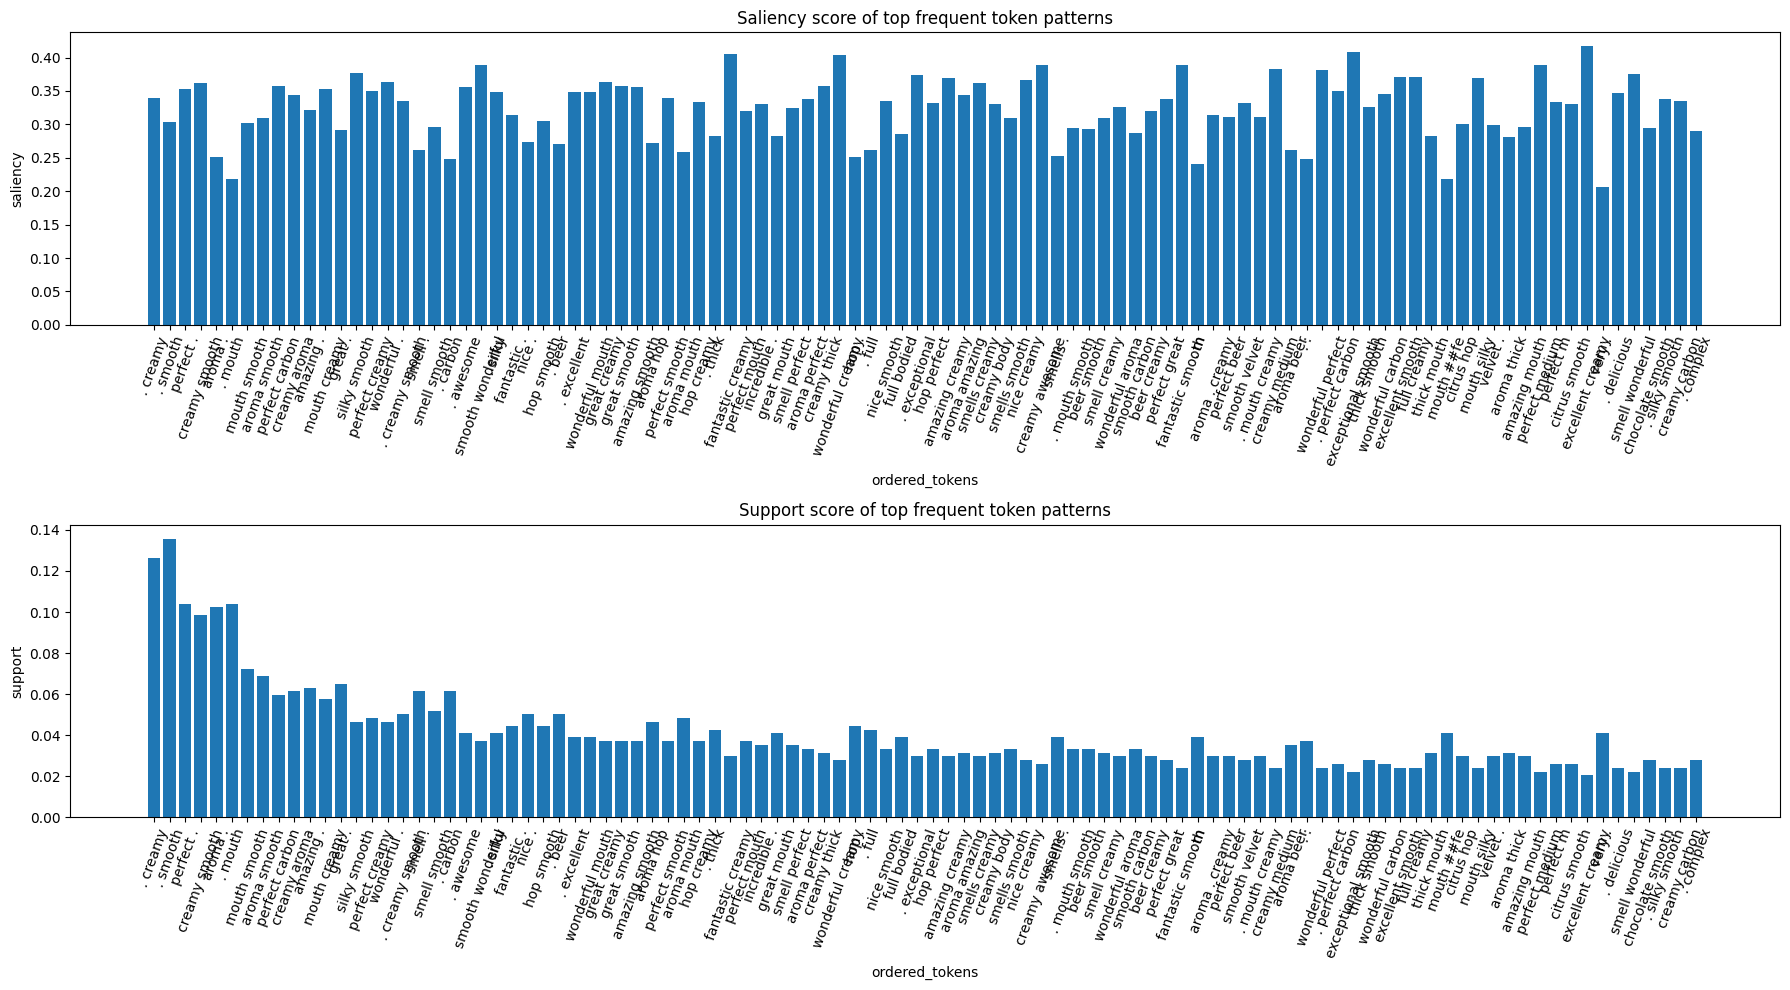

In [40]:
# Convert selected token lists to plot labels.
labels = two_grams["ordered_tokens"].apply(lambda x: " ".join(x))

fig, axes = plt.subplots(2, 1, figsize=(18,10))  # Two vertically stacked panels.

# Plot the selected patterns in the first panel.
axes[0].bar(labels, two_grams["saliency_score"])
axes[0].set_xlabel("ordered_tokens")
axes[0].set_ylabel("saliency")
axes[0].set_title("Saliency score of top frequent token patterns")
axes[0].tick_params(axis="x", rotation=70)

# Plot the second pattern metric.
axes[1].bar(labels, two_grams["support"])  # Second panel uses the corresponding pattern data.
axes[1].set_xlabel("ordered_tokens")
axes[1].set_ylabel("support")
axes[1].set_title("Support score of top frequent token patterns")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

### Extract Token-Level Hidden States

The extraction function collects the selected pattern-token representations at specified encoder layers.

In [41]:
@torch.no_grad()
def extract_itemset_hidden_states(
    model,
    tokenizer,
    itemsets_token_ids, # Token-ID sequences for the mined patterns.
    device,
    layers=(11, 12),
    context_mode="isolated",     # Select isolated or templated model input.
    template_prefix="This beer is",
    batch_size=32,
    num_labels=4,
):
    """
    Returns:
      out: dict layer_idx -> list[np.ndarray of shape (itemset_len, hidden_dim)]
      logits_out: np.ndarray [n_itemsets, num_labels]
    """

    model.eval()

    cls_id = tokenizer.cls_token_id
    sep_id = tokenizer.sep_token_id
    pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0

    if context_mode == "isolated":
        base_ids = []
        token_start = 1
    elif context_mode == "template":
        base_ids = tokenizer(template_prefix, add_special_tokens=False).input_ids
        token_start = 1 + len(base_ids)
    else:
        raise ValueError("context_mode must be 'isolated' or 'template'")

    out = {L: [] for L in layers}
    logits_out = []

    for start in range(0, len(itemsets_token_ids), batch_size):
        batch_itemsets = itemsets_token_ids[start:start + batch_size]

        input_ids_list = []
        token_ranges = []

        for ids in batch_itemsets:
            ids = [int(t) for t in ids]

            full_ids = [cls_id] + base_ids + ids + [sep_id]
            input_ids_list.append(full_ids)

            # Locate the pattern-token positions in the model input.
            token_ranges.append((token_start, token_start + len(ids)))

        max_len = max(len(x) for x in input_ids_list)

        padded_input_ids = []
        attention_masks = []
        token_type_ids = []

        for ids in input_ids_list:
            pad_len = max_len - len(ids)
            padded_input_ids.append(ids + [pad_id] * pad_len)
            attention_masks.append([1] * len(ids) + [0] * pad_len)
            token_type_ids.append([0] * max_len)

        input_ids = torch.tensor(padded_input_ids, dtype=torch.long, device=device)
        attention_mask = torch.tensor(attention_masks, dtype=torch.long, device=device)
        token_type_ids = torch.tensor(token_type_ids, dtype=torch.long, device=device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_hidden_states=True,
            return_dict=True,
        )

        if hasattr(outputs, "logits"):
            logits_out.append(outputs.logits.detach().cpu().numpy())
        else:
            bsz = input_ids.shape[0]
            logits_out.append(np.full((bsz, num_labels), np.nan, dtype=float))

        hs = outputs.hidden_states

        for b_idx, (s, e) in enumerate(token_ranges):
            for L in layers:
                vecs = hs[L][b_idx, s:e, :].detach().cpu().numpy()   # Pattern-token representation shape: [n_tokens, hidden_size].
                out[L].append(vecs)

    logits_out = np.vstack(logits_out)

    return out, logits_out

### Extract Hidden States in Isolated and Templated Contexts

Patterns are processed by pretrained and fine-tuned BERT, both in isolation and after a fixed sentence prefix.

In [42]:
layers = (5, 8, 11, 12)
itemset_ids = two_grams["ordered_ids"].tolist()

# Extract pretrained representations.
pt_iso, pt_logits_iso = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
pt_tpl, pt_logits_tpl = extract_itemset_hidden_states(
    pt_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

# Extract fine-tuned representations.
ft_iso, ft_logits_iso = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="isolated"
)
ft_tpl, ft_logits_tpl = extract_itemset_hidden_states(
    ft_bert, tokenizer, itemset_ids, device, layers=layers, context_mode="template"
)

### Add Hidden-State Representations to the DataFrame

In [43]:
for L in layers:
    two_grams[f"pt_iso_l{L}"] = list(pt_iso[L])
    two_grams[f"pt_tpl_l{L}"] = list(pt_tpl[L])
    two_grams[f"ft_iso_l{L}"] = list(ft_iso[L])
    two_grams[f"ft_tpl_l{L}"] = list(ft_tpl[L])

### Compare Pretrained and Fine-Tuned Layer-12 Representations

Mean-pooled representations are compared using cosine and Euclidean distances for each selected pattern.

In [44]:
def pool(x):
    x = np.asarray(x)
    return x.mean(axis=0) if x.ndim == 2 else x

def cos_shift(pt, ft):
    a = pool(pt)
    b = pool(ft)
    cos = np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))
    return 1 - cos

def euc_dist(pt, ft):
    a = pool(pt)
    b = pool(ft)
    return np.linalg.norm(a - b)

layers = (5, 8, 11, 12)

top = two_grams.sort_values("support", ascending=False).head(30).copy()

for L in layers:
    top[f"cos_shift_iso_l{L}"] = [
        cos_shift(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_iso_l{L}"], top[f"ft_iso_l{L}"])
    ]

    top[f"euc_iso_l{L}"] = [
        euc_dist(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_iso_l{L}"], top[f"ft_iso_l{L}"])
    ]

    top[f"cos_shift_tpl_l{L}"] = [
        cos_shift(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_tpl_l{L}"], top[f"ft_tpl_l{L}"])
    ]

    top[f"euc_tpl_l{L}"] = [
        euc_dist(pt, ft) if pt is not None and ft is not None else None
        for pt, ft in zip(top[f"pt_tpl_l{L}"], top[f"ft_tpl_l{L}"])
    ]

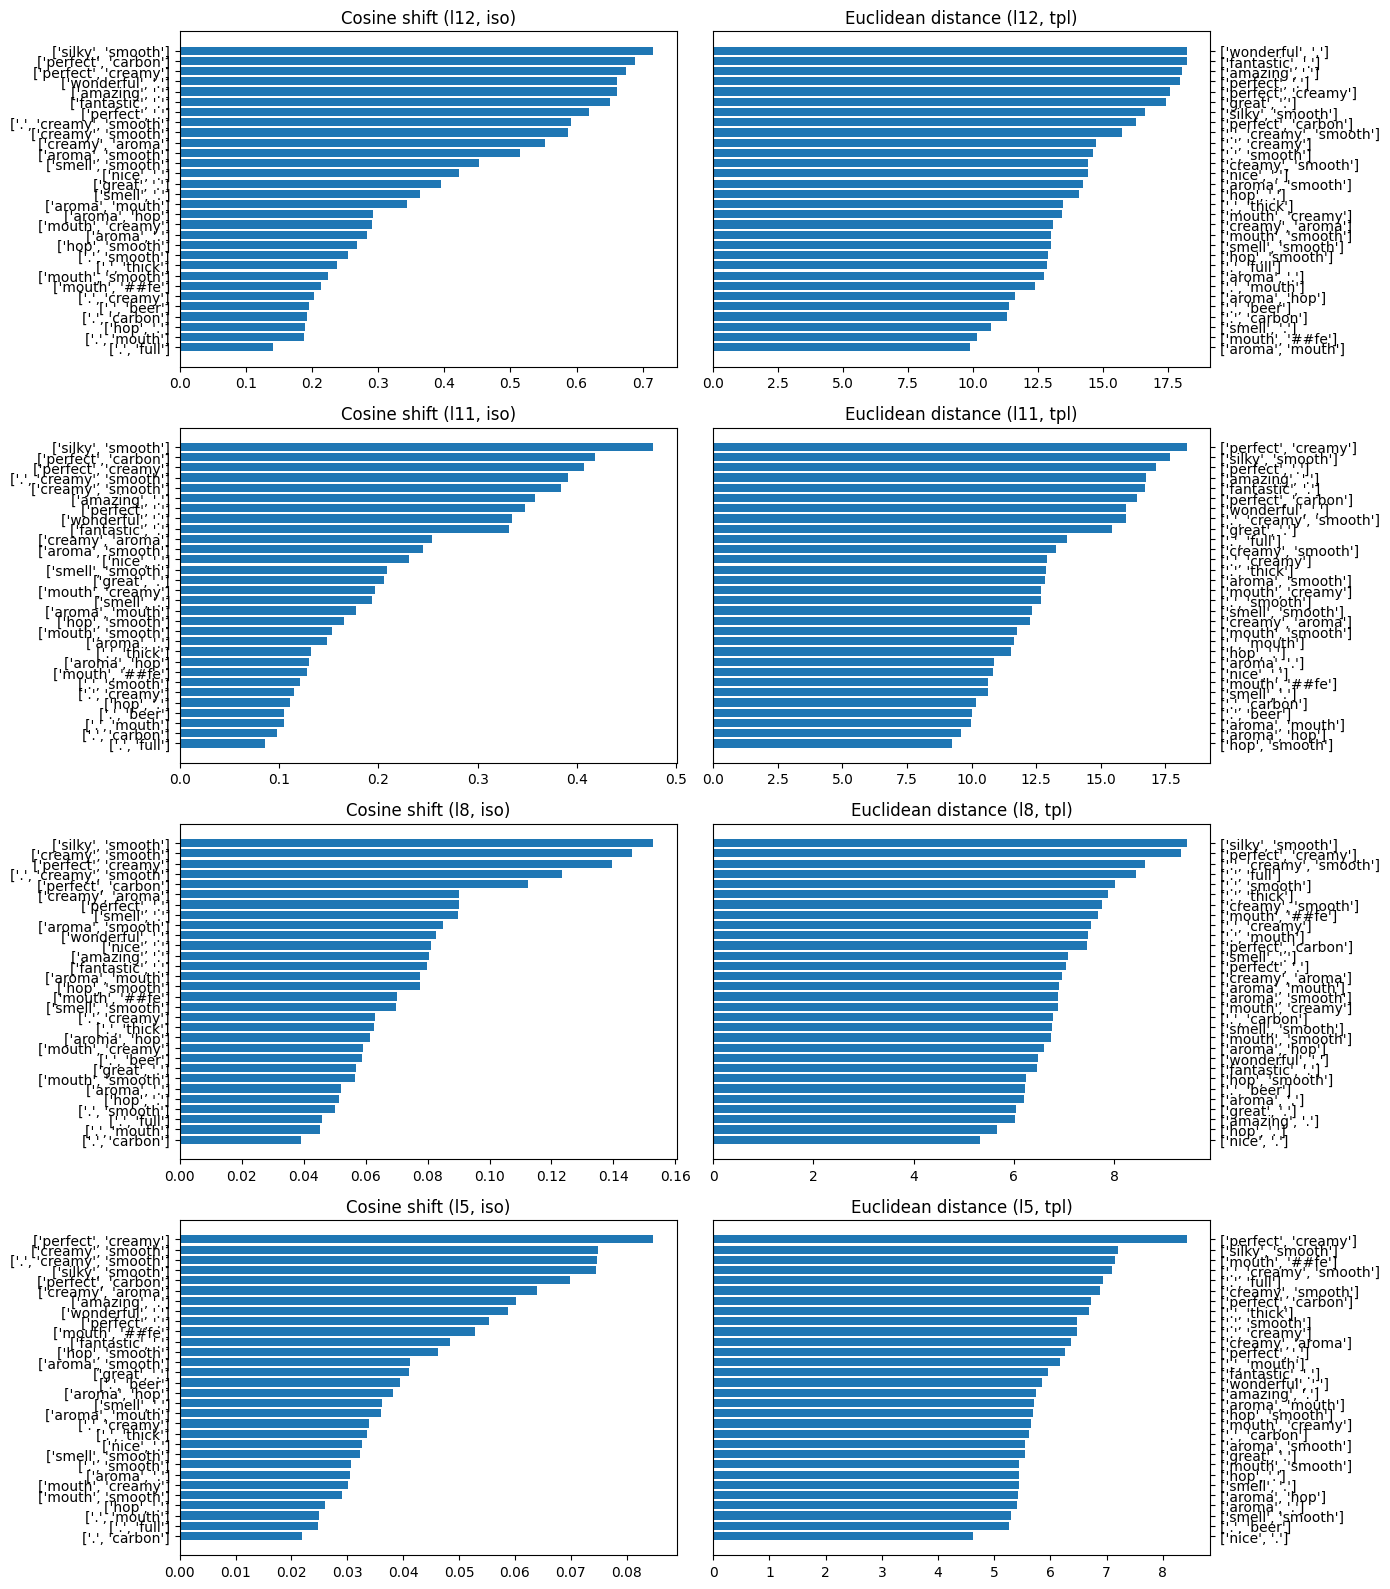

In [45]:
# Visualize representation-distance changes.

layers = (12,11,8,5)

fig, axes = plt.subplots(len(layers), 2, figsize=(14, 4 * len(layers)))
plt.subplots_adjust(wspace=0.6, hspace=0.4)

for i, L in enumerate(layers):
    # Cosine-distance panel.
    s1 = top.sort_values(f"cos_shift_iso_l{L}", ascending=False)
    axes[i, 0].barh(range(len(s1)), s1[f"cos_shift_iso_l{L}"])
    axes[i, 0].set_yticks(range(len(s1)))
    axes[i, 0].set_yticklabels(s1.ordered_tokens)
    axes[i, 0].set_title(f"Cosine shift (l{L}, iso)")
    axes[i, 0].invert_yaxis()

    # Euclidean-distance panel.
    s2 = top.sort_values(f"euc_tpl_l{L}", ascending=False)
    axes[i, 1].barh(range(len(s2)), s2[f"euc_tpl_l{L}"])
    axes[i, 1].set_yticks(range(len(s2)))
    axes[i, 1].set_yticklabels(s2.ordered_tokens)
    axes[i, 1].set_title(f"Euclidean distance (l{L}, tpl)")
    axes[i, 1].invert_yaxis()

    # Offset right-side labels to reduce overlap.
    axes[i, 1].yaxis.tick_right()

plt.tight_layout()

---

**Experiment 1 outputs.** Class-specific frequent patterns remain available in `freq_itemsets_by_class[0]` through `[3]` and in the four `freq_itemsets_class*_10` DataFrames. The next section compares neighbours of the mined patterns in pretrained and fine-tuned BERT.

---
## Experiment 2: Nearest-Neighbour Changes After Fine-Tuning

This experiment measures changes in the distances between mined patterns and their nearest WordPiece-token neighbours, using the neighbours selected in **fine-tuned (FT) BERT** as a fixed reference set.

1. **Select patterns.** Include every mined single-token or multi-token itemset (length 1–4) from each of the four predicted classes, retaining its support and saliency metrics.
2. **Extract representations.** Compute mean-pooled hidden states for each pattern in pretrained (PT) and FT BERT at layers **5, 8, 11, and 12**, using isolated (`iso`) and templated (`tpl`) contexts.
3. **Construct a shared neighbour pool.** Collect the individual WordPiece token IDs occurring in mined patterns from all four classes. Extract their PT and FT hidden states in both contexts at the same layers.
4. **Select FT neighbours.** For each pattern, context, and layer, identify the **10 and 30 nearest individual tokens in FT space** by cosine similarity. Exclude token IDs belonging to the pattern itself.
5. **Compare fixed token pairs.** Retain the FT-selected neighbour IDs and compute cosine and Euclidean distances between the pattern and those same neighbours in PT space.
6. **Measure distance changes.** For each pair, calculate `absolute_shift = abs(distance_PT - distance_FT)` and `signed_contraction = distance_PT - distance_FT`. A positive signed contraction indicates a smaller distance in FT; a negative value indicates a larger distance in FT.
7. **Rank patterns.** Aggregate distance changes over the selected 10 or 30 neighbours. Rank patterns within each predicted class, layer, and context, alongside their FP-Growth support and saliency metrics.

The candidate neighbour pool contains WordPiece tokens from the mined patterns rather than the complete BERT vocabulary. Multi-token FP-Growth itemsets are unordered co-occurrences; `ordered_ids` provides an observed ordering for representation extraction. Distance changes describe representation geometry and do not, on their own, establish causal shortcut reliance.

**Terminology:** S1 top-10 refers to the ten salient token IDs selected per review; NN-10 and NN-30 refer to the numbers of nearest neighbours in representation space.

In [46]:
# Configure layers, contexts, and neighbour counts for Experiment 2.
NN_LAYERS = (5, 8, 11, 12)
NN_CONTEXTS = {"iso": "isolated", "tpl": "template"}
NN_K_VALUES = (10, 30)
NN_TEMPLATE_PREFIX = "This beer is"  # Sentence prefix used for templated representations.
NN_BATCH_SIZE = 32

# Include every mined pattern, including single-token itemsets.
# FP-Growth results are not truncated to a fixed top-N subset.

# Extract token-level hidden states for each pattern.
# Mean-pool the pattern-token states for neighbour comparisons.
def nn_extract_mean_states(model, pattern_ids, context, batch_size=NN_BATCH_SIZE):
    if not pattern_ids:
        raise ValueError("Cannot extract embeddings for an empty list of patterns")

    hs, _ = extract_itemset_hidden_states(
        model=model,
        tokenizer=tokenizer,
        itemsets_token_ids=pattern_ids,
        device=device,
        layers=NN_LAYERS,
        context_mode=NN_CONTEXTS[context],
        template_prefix=NN_TEMPLATE_PREFIX,
        batch_size=batch_size,
    )
    return {
        L: np.vstack([np.asarray(x, dtype=np.float32).mean(axis=0)
                      for x in hs[L]]).astype(np.float32)
        for L in NN_LAYERS
    }


def nn_normalize_rows(matrix):
    matrix = np.asarray(matrix, dtype=np.float32)
    return matrix / np.maximum(np.linalg.norm(matrix, axis=1, keepdims=True), 1e-12)


### Shared Neighbour Vocabulary

The candidate pool consists of individual WordPiece token IDs appearing in the mined patterns across all four predicted classes. The same candidate IDs are represented in PT and FT BERT, using the same layers and context settings. The pool is a subset of the BERT vocabulary.

In [47]:
# Create one WordPiece candidate pool across all four predicted classes.
NN_TOKEN_IDS = sorted({
    int(token_id)
    for c in range(4)
    for ids in freq_itemsets_by_class[c]["ordered_ids"]
    for token_id in ids
})
if len(NN_TOKEN_IDS) < max(NN_K_VALUES) + 4:
    print(f"Note: only {len(NN_TOKEN_IDS)} candidate tokens; some patterns may have fewer than 30 eligible neighbours.")
if len(NN_TOKEN_IDS) < 2:
    raise ValueError("Need at least two mined token IDs to compute neighbours")

NN_TOKEN_LABELS = tokenizer.convert_ids_to_tokens(NN_TOKEN_IDS)
NN_TOKEN_IDS_ARRAY = np.asarray(NN_TOKEN_IDS, dtype=int)

# Compute pretrained and fine-tuned candidate-token representations.
# Store candidate representations separately from Experiment 1 arrays.
nn_token_vectors = {}  # (model_type, context, layer) -> [n_tokens, hidden_size]
for context in NN_CONTEXTS:
    single_token_itemsets = [[tok_id] for tok_id in NN_TOKEN_IDS]
    for model_type, model in (("pt", pt_bert), ("ft", ft_bert)):
        print(f"Neighbour vocabulary: {model_type}, {context}, {len(NN_TOKEN_IDS)} tokens")
        states = nn_extract_mean_states(model, single_token_itemsets, context)
        for L in NN_LAYERS:
            nn_token_vectors[(model_type, context, L)] = states[L]

del single_token_itemsets
print("Shared neighbour vocabulary size:", len(NN_TOKEN_IDS))


Neighbour vocabulary: pt, iso, 232 tokens
Neighbour vocabulary: ft, iso, 232 tokens
Neighbour vocabulary: pt, tpl, 232 tokens
Neighbour vocabulary: ft, tpl, 232 tokens
Shared neighbour vocabulary size: 232


### Fine-Tuned Neighbour Selection and Pretrained Distance Comparison

For each class and each pattern, nearest neighbours are selected in FT BERT at a given layer and context. The selected token IDs remain fixed while cosine and Euclidean distances are measured in PT and FT BERT. Results are computed for both 10 and 30 neighbours.

In [48]:
def nn_class_distance_comparison(predicted_class):
    """Compare all mined patterns in one class to their FT-selected neighbours."""
    source = freq_itemsets_by_class[predicted_class].reset_index(drop=True)
    if source.empty:
        return pd.DataFrame()

    pattern_ids = [list(map(int, ids)) for ids in source["ordered_ids"]]
    rows = []

    for context in NN_CONTEXTS:
        print(f"  Class {predicted_class}, context {context}: {len(pattern_ids)} patterns")
        ft_patterns = nn_extract_mean_states(ft_bert, pattern_ids, context)
        pt_patterns = nn_extract_mean_states(pt_bert, pattern_ids, context)

        for L in NN_LAYERS:
            ft_queries = ft_patterns[L]
            pt_queries = pt_patterns[L]
            ft_candidates = nn_token_vectors[("ft", context, L)]
            pt_candidates = nn_token_vectors[("pt", context, L)]

            # Select nearest neighbours in fine-tuned space using cosine similarity.
            ft_queries_norm = nn_normalize_rows(ft_queries)
            pt_queries_norm = nn_normalize_rows(pt_queries)
            ft_candidates_norm = nn_normalize_rows(ft_candidates)
            pt_candidates_norm = nn_normalize_rows(pt_candidates)
            sims = ft_queries_norm @ ft_candidates_norm.T

            for i, ids in enumerate(pattern_ids):
                # Exclude the anchor pattern's constituent token IDs.
                cosine_similarities = sims[i].copy()
                cosine_similarities[np.isin(NN_TOKEN_IDS_ARRAY, ids)] = -np.inf
                available = np.flatnonzero(np.isfinite(cosine_similarities))
                if len(available) == 0:
                    continue
                n_select = min(max(NN_K_VALUES), len(available))
                candidate_indices = np.argsort(cosine_similarities)[-n_select:][::-1]

                ft_nn_cos_dist = 1.0 - (ft_candidates_norm[candidate_indices] @ ft_queries_norm[i])
                pt_nn_cos_dist = 1.0 - (pt_candidates_norm[candidate_indices] @ pt_queries_norm[i])
                ft_nn_cos_dist = np.maximum(ft_nn_cos_dist, 0.0)
                pt_nn_cos_dist = np.maximum(pt_nn_cos_dist, 0.0)
                ft_nn_euclidean = np.linalg.norm(ft_candidates[candidate_indices] - ft_queries[i], axis=1)
                pt_nn_euclidean = np.linalg.norm(pt_candidates[candidate_indices] - pt_queries[i], axis=1)

                for k in NN_K_VALUES:
                    n = min(k, n_select)
                    cosine_ft = ft_nn_cos_dist[:n]
                    cosine_pt = pt_nn_cos_dist[:n]
                    euclidean_ft = ft_nn_euclidean[:n]
                    euclidean_pt = pt_nn_euclidean[:n]
                    cos_signed = cosine_pt - cosine_ft  # Positive values indicate a smaller distance in fine-tuned space.
                    euc_signed = euclidean_pt - euclidean_ft

                    row = {
                        "predicted_class": predicted_class,
                        "rating": ID_TO_RATING[predicted_class],
                        "pattern_text": " ".join(source.iloc[i]["ordered_tokens"]),
                        "ordered_tokens": list(source.iloc[i]["ordered_tokens"]),
                        "ordered_ids": ids,
                        "length": int(source.iloc[i]["length"]),
                        "support": float(source.iloc[i]["support"]),
                        "support_count": int(source.iloc[i]["support_count"]),
                        "saliency_score": float(source.iloc[i]["saliency_score"]),
                        "score": float(source.iloc[i]["score"]),
                        "layer": L,
                        "context": context,
                        "k": k,
                        "actual_k": n,
                        "ft_nn_token_ids": NN_TOKEN_IDS_ARRAY[candidate_indices[:n]].tolist(),
                        "ft_nn_tokens": [NN_TOKEN_LABELS[j] for j in candidate_indices[:n]],
                        "ft_nn_cosine_distances": cosine_ft.tolist(),
                        "pt_same_nn_cosine_distances": cosine_pt.tolist(),
                        "signed_cosine_contractions": cos_signed.tolist(),
                        "absolute_cosine_shifts": np.abs(cos_signed).tolist(),
                        "mean_abs_cosine_shift": float(np.abs(cos_signed).mean()),
                        "mean_signed_cosine_contraction": float(cos_signed.mean()),
                        "ft_nn_euclidean_distances": euclidean_ft.tolist(),
                        "pt_same_nn_euclidean_distances": euclidean_pt.tolist(),
                        "signed_euclidean_contractions": euc_signed.tolist(),
                        "absolute_euclidean_shifts": np.abs(euc_signed).tolist(),
                        "mean_abs_euclidean_shift": float(np.abs(euc_signed).mean()),
                        "mean_signed_euclidean_contraction": float(euc_signed.mean()),
                    }
                    rows.append(row)

    return pd.DataFrame(rows)


In [49]:
# Compute the nearest-neighbour comparisons for each predicted class.
_nn_class_results = []
for c in range(4):
    print(f"\nComputing FT -> PT neighbour comparison for class {c} (palate {ID_TO_RATING[c]:.1f})")
    _nn_class_results.append(nn_class_distance_comparison(c))

nn_shift_df = pd.concat(_nn_class_results, ignore_index=True)
if nn_shift_df.empty:
    raise ValueError("No neighbour comparisons were produced")

# Separate complete NN-10 and NN-30 results into directly accessible DataFrames.
# Each table retains all classes, layers, contexts, patterns, and distance metrics.
nn_10_df = nn_shift_df.loc[nn_shift_df["k"] == 10].copy()
nn_30_df = nn_shift_df.loc[nn_shift_df["k"] == 30].copy()

# Provide separate DataFrames for each predicted class and neighbour count.
nn_class0_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 0].copy()
nn_class1_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 1].copy()
nn_class2_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 2].copy()
nn_class3_10_df = nn_10_df.loc[nn_10_df["predicted_class"] == 3].copy()

nn_class0_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 0].copy()
nn_class1_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 1].copy()
nn_class2_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 2].copy()
nn_class3_30_df = nn_30_df.loc[nn_30_df["predicted_class"] == 3].copy()

print("\nResult counts by class, context, layer, and neighbour count:")
print(nn_shift_df.groupby(["predicted_class", "context", "layer", "k"]).size().to_string())



Computing FT -> PT neighbour comparison for class 0 (palate 0.4)
  Class 0, context iso: 191 patterns
  Class 0, context tpl: 191 patterns

Computing FT -> PT neighbour comparison for class 1 (palate 0.6)
  Class 1, context iso: 438 patterns
  Class 1, context tpl: 438 patterns

Computing FT -> PT neighbour comparison for class 2 (palate 0.8)
  Class 2, context iso: 411 patterns
  Class 2, context tpl: 411 patterns

Computing FT -> PT neighbour comparison for class 3 (palate 1.0)
  Class 3, context iso: 439 patterns
  Class 3, context tpl: 439 patterns

Result counts by class, context, layer, and neighbour count:
predicted_class  context  layer  k 
0                iso      5      10    191
                                 30    191
                          8      10    191
                                 30    191
                          11     10    191
                                 30    191
                          12     10    191
                                 30    19

### Nearest-Neighbour Results as DataFrames

`nn_10_df` and `nn_30_df` contain the complete nearest-neighbour comparisons for 10 and 30 fine-tuned neighbours, respectively. Each DataFrame includes all four predicted classes, layers 5, 8, 11, and 12, and both isolated (`iso`) and templated (`tpl`) contexts.

Separate class-specific DataFrames are available as `nn_class0_10_df` through `nn_class3_10_df` and `nn_class0_30_df` through `nn_class3_30_df`. Each row represents one mined pattern at a specific layer and context. Columns retain support, saliency, score, the FT-selected neighbour tokens, and the PT/FT distance comparisons.

The ranking metrics are `mean_abs_cosine_shift`, `mean_abs_euclidean_shift`, `mean_signed_cosine_contraction`, and `mean_signed_euclidean_contraction`. Signed contraction is calculated as pretrained distance minus fine-tuned distance; positive values indicate contraction after fine-tuning.

Comparisons of pattern shifts should use a consistent layer, context, and neighbour count. DataFrames can be filtered with pandas and sorted directly by any metric. No result-display helper function is required.

In [50]:
# Example: top 30 shifted patterns for predicted class 3 at layer 12 (templated, NN-30).
nn_class3_30_df.query("layer == 12 and context == 'tpl'").sort_values(
    "mean_abs_cosine_shift", ascending=False
)[[
    "pattern_text", "length", "support", "saliency_score", "score",
    "mean_abs_cosine_shift", "mean_abs_euclidean_shift",
    "mean_signed_cosine_contraction", "mean_signed_euclidean_contraction",
    "ft_nn_tokens", "actual_k",
]].head(30)


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,mean_signed_euclidean_contraction,ft_nn_tokens,actual_k
23225,fantastic creamy smooth,3,0.014870,0.367338,0.005462,0.371127,8.570167,-0.330962,-8.366165,"[perfect, gorgeous, outstanding, awesome, deli...",30
23165,perfect smooth,2,0.037175,0.339977,0.012639,0.361142,8.528480,-0.352415,-8.528480,"[gorgeous, fantastic, outstanding, awesome, de...",30
23541,amazing smooth creamy,3,0.014870,0.378514,0.005628,0.360392,8.389255,-0.320993,-8.180264,"[perfect, gorgeous, fantastic, outstanding, aw...",30
23477,. perfect carbon,3,0.026022,0.349540,0.009096,0.359186,8.397474,-0.345540,-8.397474,"[gorgeous, fantastic, awesome, outstanding, de...",30
23433,. creamy awesome,3,0.014870,0.375806,0.005588,0.357632,8.165890,-0.313939,-7.938069,"[perfect, gorgeous, fantastic, outstanding, de...",30
23479,smell perfect carbon,3,0.014870,0.308354,0.004585,0.355127,8.534240,-0.346369,-8.534240,"[gorgeous, fantastic, outstanding, awesome, de...",30
23503,wonderful perfect,2,0.024164,0.381240,0.009212,0.344908,8.564713,-0.334914,-8.564713,"[gorgeous, fantastic, outstanding, awesome, de...",30
23465,perfect carbon,2,0.059480,0.357832,0.021284,0.344101,8.205270,-0.331511,-8.205270,"[gorgeous, fantastic, awesome, outstanding, de...",30
23259,perfect stout,2,0.016729,0.409066,0.006843,0.343329,7.868551,-0.333762,-7.868551,"[gorgeous, fantastic, awesome, outstanding, de...",30
23163,perfect creamy,2,0.048327,0.349178,0.016875,0.343218,8.420907,-0.334029,-8.420907,"[gorgeous, fantastic, outstanding, awesome, de...",30


In [51]:
# Example: top 30 shifted single-token patterns for class 0 at layer 5 (isolated, NN-10).
nn_class0_10_df.query("layer == 5 and context == 'iso' and length == 1").sort_values(
    "mean_abs_euclidean_shift", ascending=False
)[[
    "pattern_text", "length", "support", "saliency_score", "score",
    "mean_abs_cosine_shift", "mean_abs_euclidean_shift",
    "mean_signed_cosine_contraction", "mean_signed_euclidean_contraction",
    "ft_nn_tokens", "actual_k",
]].head(30)


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_abs_euclidean_shift,mean_signed_cosine_contraction,mean_signed_euclidean_contraction,ft_nn_tokens,actual_k
124,smells,1,0.078767,0.268253,0.021130,0.025243,0.863245,-0.023335,-0.852225,"[smelled, smelling, spicy, spices, hazy, ##bbl...",10
118,extremely,1,0.030822,0.275024,0.008477,0.024314,0.822159,-0.018602,-0.696695,"[incredibly, massive, very, disappointing, flo...",10
58,pour,1,0.047945,0.225767,0.010824,0.022144,0.810387,-0.022144,-0.810387,"[poured, drink, balanced, aroma, wow, coating,...",10
34,citrus,1,0.027397,0.286840,0.007859,0.017743,0.632666,-0.016417,-0.632666,"[sweetness, tropical, aroma, enjoyable, yeast,...",10
24,thick,1,0.044521,0.325916,0.014510,0.020265,0.628791,-0.018798,-0.617450,"[massive, cheap, dense, soft, spicy, solid, fa...",10
126,nothing,1,0.027397,0.259020,0.007096,0.018939,0.626386,-0.018939,-0.626386,"[grassy, subdued, wheat, lots, exceptional, sl...",10
112,slight,1,0.030822,0.289429,0.008921,0.014449,0.571265,-0.014449,-0.571265,"[faint, massive, ##bbly, spices, hazy, soft, d...",10
134,grain,1,0.058219,0.266827,0.015534,0.026372,0.543314,0.026372,0.543314,"[massive, syrup, spices, bread, hazy, bitter, ...",10
122,poor,1,0.027397,0.466537,0.012782,0.020326,0.533564,-0.016040,-0.475242,"[rich, superb, weak, brilliant, sour, perfect,...",10
26,feel,1,0.027397,0.248150,0.006799,0.016251,0.531318,-0.016251,-0.531318,"[smells, looks, smell, texture, mild, taste, s...",10


In [52]:
# Example: class 3 multi-token patterns ranked by signed cosine contraction (NN-30).
nn_class3_30_df.query("layer == 12 and context == 'tpl' and length > 1").sort_values(
    "mean_signed_cosine_contraction", ascending=False
)[[
    "pattern_text", "length", "support", "saliency_score", "score",
    "mean_abs_cosine_shift", "mean_signed_cosine_contraction",
    "ft_nn_tokens", "actual_k",
]].head(30)


,pattern_text,length,support,saliency_score,score,mean_abs_cosine_shift,mean_signed_cosine_contraction,ft_nn_tokens,actual_k
23437,hop .,2,0.044610,0.251870,0.011236,0.248993,0.248993,"[citrus, white, pleasant, soft, spicy, well, r...",30
23257,stout .,2,0.024164,0.289690,0.007000,0.237656,0.237656,"[pleasant, white, citrus, soft, well, spicy, s...",30
23231,good .,2,0.026022,0.231479,0.006024,0.229310,0.229310,"[pleasant, silky, well, nice, big, strong, cle...",30
23299,citrus .,2,0.024164,0.296846,0.007173,0.221963,0.221963,"[pleasant, white, soft, fruits, well, spicy, s...",30
23553,floral .,2,0.018587,0.253569,0.004713,0.212528,0.212528,"[pleasant, white, citrus, spicy, soft, sweet, ...",30
23149,lace .,2,0.018587,0.230926,0.004292,0.211097,0.211097,"[well, grain, clear, citrus, thick, bread, a, ...",30
23507,velvet .,2,0.029740,0.299239,0.008899,0.180640,0.180640,"[clear, silky, grain, thick, well, sweet, last...",30
23387,sweet .,2,0.014870,0.229709,0.003416,0.179691,0.179691,"[pleasant, soft, citrus, white, spicy, well, o...",30
23611,hazy .,2,0.018587,0.248409,0.004617,0.176025,0.176025,"[lacking, weak, sharp, stale, poor, somewhat, ...",30
23271,light .,2,0.016729,0.253219,0.004236,0.153573,0.153573,"[lacking, hazy, sharp, average, white, slight,...",30


**Experiment 2 outputs.** `nn_10_df` and `nn_30_df` contain all nearest-neighbour comparisons. Class-specific results are available in `nn_class0_10_df` through `nn_class3_10_df` and `nn_class0_30_df` through `nn_class3_30_df`. The tables retain the fine-tuned neighbour IDs, their token labels, and distances for those same neighbour pairs in pretrained and fine-tuned BERT.